# ADMM Convergence Study
Sweeps over:
- `p_cost` — quadratic regularisation on P variables (breaks degeneracy)
- `tolerance` — ADMM convergence threshold
- `rho` — initial penalty parameter (adaptive rho enabled)

For each combination records:
- Iteration count to convergence
- Final residual
- Max individual cost difference vs centralized
- Total cost distortion from regularisation
- Residual trajectory (convergence curve)

## 1. Setup

In [1]:
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
warnings.filterwarnings('ignore')

REPO = Path('/Users/catharinahente/Documents/Github/p2p-energy-trading-illustrative')
sys.path.insert(0, str(REPO))

from scenarios import make_scenario
from algo      import centralized, distributed

plt.rcParams.update({
    'font.family':       'sans-serif',
    'font.size':         9,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'pdf.fonttype':      42,
})

SEED   = 42
SEASON = 'winter'
BASE_RHO = 2.0          # initial rho (adaptive rho enabled)
BASE_TOL = 1e-7         # baseline tolerance
BASE_PCOST = 1e-4       # baseline p_cost
MAX_ITER   = 20000      # max iterations per run

print('Setup complete')

Setup complete


## 2. Load scenario and centralized reference

In [2]:
# Build base scenario
data_base = make_scenario(SEASON, seed=SEED, resolution_h=0.5)
N = len(data_base['demand'])
names = data_base['prosumer_names']

# Centralized reference at base p_cost
result_c_base = centralized(data_base)
J_c_base = result_c_base['costs']
print(f'Centralized reference: {J_c_base.sum():.4f} EUR')
for i in range(N):
    print(f'  P{i+1} ({names[i]}): {J_c_base[i]:.4f} EUR')

Building winter scenario (T=48, dt=0.5h, resolution=30min)...
  P1: Residential ++ (bus 5)
    HP: Air_Alternative_1 (Air alternative, Hanover)
  P2: Office building (bus 11)
    ⚠ No EV activity detected — using fallback schedule
  P3: Residential HP only (bus 17)
    HP: Air_Semi-Parallel_1 (Air semi-parallel, Hanover)
  P4: Residential PV only (bus 32)
  Done. N=4, T=48, dt=0.5h, max_demand=6.3 kW
Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2806500
Academic license 2806500 - for non-commercial use only - registered to ch___@ethz.ch
Centralized reference: 58.6009 EUR
  P1 (Residential ++): 7.4449 EUR
  P2 (Office building): 37.1328 EUR
  P3 (Residential HP only): 3.2737 EUR
  P4 (Residential PV only): 10.7494 EUR


## 3. Sweep 1 — p_cost effect
Fixed rho and tolerance, vary p_cost to see degeneracy breaking and cost distortion.

In [10]:
import time

p_costs = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
sweep_pcost = []

# Centralized reference at base p_cost — run once
r_c_ref = centralized(data_base)

for pc in p_costs:
    print(f'p_cost={pc:.0e} ...', end=' ', flush=True)
    data_pc = {**data_base, 'p_cost': pc}

    t0  = time.time()
    r_c = centralized(data_pc)
    r_d = distributed(data_pc, rho=2.0, tolerance=1e-5,
                      max_iterations=20000,
                      adaptive_rho=True, log_history=True)
    dt  = time.time() - t0

    J_c = r_c['costs']
    J_d = r_d['costs']
    sweep_pcost.append({
        'p_cost':       pc,
        'iterations':   r_d['iterations'],
        'residual':     r_d['residual'],
        'converged':    r_d.get('converged', True),
        'cost_distort': float(J_d.sum() - J_c.sum()),
        'max_ind_diff': float(np.max(np.abs(J_d - J_c))),
        'history':      r_d.get('history', []),
    })
    print(f"iter={r_d['iterations']}  "
          f"diff={sweep_pcost[-1]['max_ind_diff']:.5f} EUR  "
          f"distort={sweep_pcost[-1]['cost_distort']:+.5f} EUR  "
          f"{dt:.1f}s")

p_cost=1e-05 ... iter=1297  diff=0.00155 EUR  distort=+0.00000 EUR  48.4s
p_cost=1e-04 ... iter=726  diff=0.00128 EUR  distort=-0.00000 EUR  23.2s
p_cost=1e-03 ... iter=423  diff=0.00027 EUR  distort=-0.00001 EUR  12.2s
p_cost=1e-02 ... iter=182  diff=0.00006 EUR  distort=-0.00001 EUR  5.3s
p_cost=1e-01 ... iter=91  diff=0.00001 EUR  distort=-0.00001 EUR  2.8s
p_cost=1e+00 ... iter=42  diff=0.00001 EUR  distort=-0.00001 EUR  1.5s


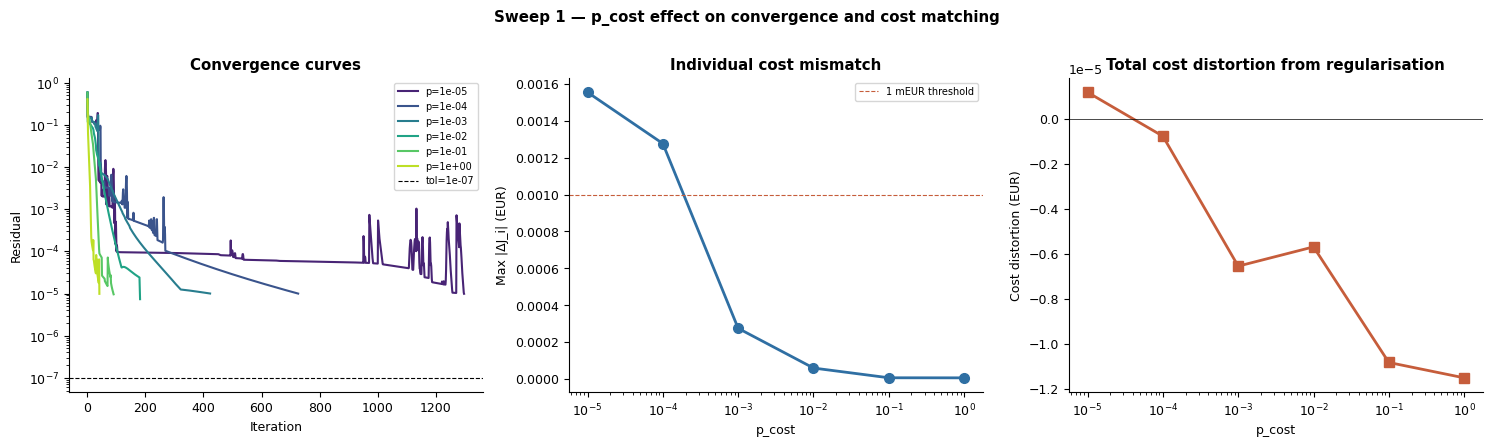

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
COLS = plt.cm.viridis(np.linspace(0.1, 0.9, len(p_costs)))

# Left: convergence curves
ax = axes[0]
for r, col in zip(sweep_pcost, COLS):
    if r['history']:
        iters = [h[0] for h in r['history']]
        resid = [h[1] for h in r['history']]
        ax.semilogy(iters, resid, color=col, lw=1.5,
                    label=f"p={r['p_cost']:.0e}")
ax.axhline(BASE_TOL, color='k', lw=0.8, ls='--', label=f'tol={BASE_TOL:.0e}')
ax.set_xlabel('Iteration'); ax.set_ylabel('Residual')
ax.set_title('Convergence curves', fontweight='bold')
ax.legend(fontsize=7)

# Middle: max individual cost diff vs p_cost
ax = axes[1]
pcs = [r['p_cost'] for r in sweep_pcost]
diffs = [r['max_ind_diff'] for r in sweep_pcost]
ax.semilogx([max(pc, 1e-8) for pc in pcs], diffs,
            'o-', color='#2F6FA3', lw=2, ms=7)
ax.set_xlabel('p_cost'); ax.set_ylabel('Max |ΔJ_i| (EUR)')
ax.set_title('Individual cost mismatch', fontweight='bold')
ax.axhline(0.001, color='#C65D3B', lw=0.8, ls='--', label='1 mEUR threshold')
ax.legend(fontsize=7)

# Right: cost distortion vs p_cost  
ax = axes[2]
distorts = [r['cost_distort'] for r in sweep_pcost]
ax.semilogx([max(pc, 1e-8) for pc in pcs], distorts,
            's-', color='#C65D3B', lw=2, ms=7)
ax.set_xlabel('p_cost'); ax.set_ylabel('Cost distortion (EUR)')
ax.set_title('Total cost distortion from regularisation', fontweight='bold')
ax.axhline(0, color='k', lw=0.5)

plt.suptitle('Sweep 1 — p_cost effect on convergence and cost matching',
             fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Sweep 2 — Tolerance effect
Fixed p_cost, vary tolerance. Shows iteration count vs accuracy tradeoff.

In [14]:
tolerances = [1e-3, 1e-4, 1e-5, 1e-6, 1e-7]
sweep_tol  = []

# Centralized reference — run once
r_c = centralized(data_base)
J_c = r_c['costs']

print(f"{'tolerance':<12} {'iter':>6} {'residual':>12} "
      f"{'max|ΔJ|(EUR)':>14} {'time(s)':>8} {'status':>8}")
print('─' * 65)

for tol in tolerances:
    print(f"  tol={tol:.0e} ...", end=' ', flush=True)
    t0  = time.time()
    r_d = distributed(data_base, rho=BASE_RHO, tolerance=tol,
                      max_iterations=50000,
                      adaptive_rho=True, log_history=True)
    t_d = time.time() - t0

    converged   = r_d.get('converged', True)
    max_diff    = float(np.max(np.abs(r_d['costs'] - J_c)))
    status      = '✓' if converged else '⚠ cap'

    print(f"iter={r_d['iterations']:>6}  "
          f"res={r_d['residual']:.2e}  "
          f"max|ΔJ|={max_diff:.5f} EUR  "
          f"{t_d:.1f}s  {status}", flush=True)

    sweep_tol.append({
        'tolerance':    tol,
        'iterations':   r_d['iterations'],
        'residual':     r_d['residual'],
        'converged':    converged,
        'max_ind_diff': max_diff,
        'history':      r_d.get('history', []),
        't_dist':       t_d,
    })

df_tol = pd.DataFrame(sweep_tol)[['tolerance','iterations','residual',
                                    'max_ind_diff','t_dist','converged']]
df_tol.columns = ['Tolerance','Iterations','Final residual',
                   'Max |ΔJ_i| EUR','Time (s)','Converged']
display(df_tol.set_index('Tolerance'))

tolerance      iter     residual   max|ΔJ|(EUR)  time(s)   status
─────────────────────────────────────────────────────────────────
  tol=1e-03 ... iter=   116  res=9.92e-04  max|ΔJ|=0.04674 EUR  4.1s  ✓
  tol=1e-04 ... iter=   206  res=9.94e-05  max|ΔJ|=0.00433 EUR  8.7s  ✓
  tol=1e-05 ... iter=   423  res=1.00e-05  max|ΔJ|=0.00027 EUR  13.0s  ✓
  tol=1e-06 ... iter=   979  res=9.90e-07  max|ΔJ|=0.00044 EUR  26.3s  ✓
  tol=1e-07 ... iter=  5661  res=1.00e-07  max|ΔJ|=0.00045 EUR  225.9s  ✓


,Iterations,Final residual,Max |ΔJ_i| EUR,Time (s),Converged
Tolerance,,,,,
1.000000e-03,116,9.918813e-04,0.046740,4.090020,True
1.000000e-04,206,9.942927e-05,0.004330,8.662105,True
1.000000e-05,423,9.998662e-06,0.000274,12.976402,True
1.000000e-06,979,9.897400e-07,0.000440,26.252094,True
1.000000e-07,5661,9.995051e-08,0.000450,225.912645,True


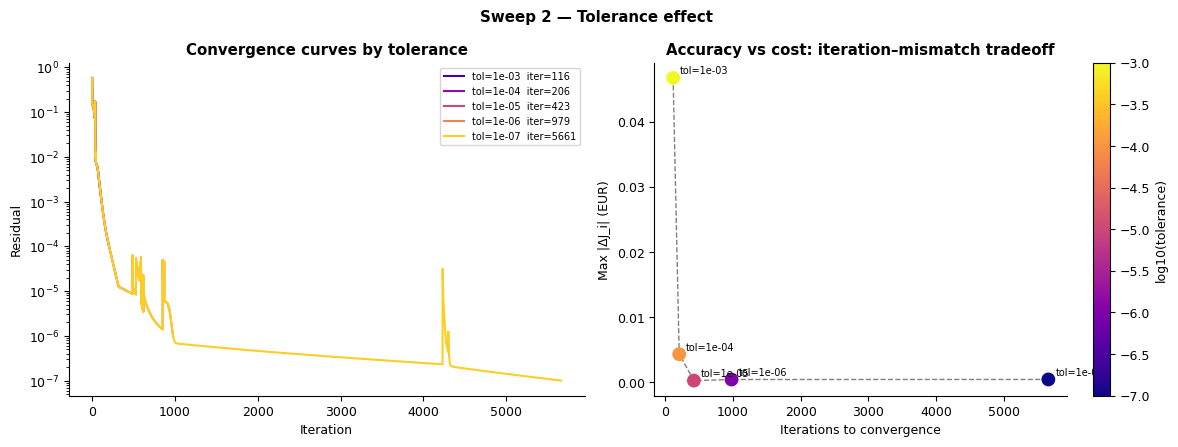

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
COLS2 = plt.cm.plasma(np.linspace(0.1, 0.9, len(tolerances)))

# Left: convergence curves
ax = axes[0]
for r, col in zip(sweep_tol, COLS2):
    if r['history']:
        iters = [h[0] for h in r['history']]
        resid = [h[1] for h in r['history']]
        ax.semilogy(iters, resid, color=col, lw=1.5,
                    label=f"tol={r['tolerance']:.0e}  iter={r['iterations']}")
ax.set_xlabel('Iteration'); ax.set_ylabel('Residual')
ax.set_title('Convergence curves by tolerance', fontweight='bold')
ax.legend(fontsize=7)

# Right: iterations vs max cost diff  
ax = axes[1]
iters_tol = [r['iterations'] for r in sweep_tol]
diffs_tol  = [r['max_ind_diff'] for r in sweep_tol]
sc = ax.scatter(iters_tol, diffs_tol,
                c=[np.log10(r['tolerance']) for r in sweep_tol],
                cmap='plasma', s=80, zorder=3)
ax.plot(iters_tol, diffs_tol, '--', color='grey', lw=1, zorder=2)
for r in sweep_tol:
    ax.annotate(f"tol={r['tolerance']:.0e}",
                (r['iterations'], r['max_ind_diff']),
                textcoords='offset points', xytext=(5,3), fontsize=7)
ax.set_xlabel('Iterations to convergence')
ax.set_ylabel('Max |ΔJ_i| (EUR)')
ax.set_title('Accuracy vs cost: iteration–mismatch tradeoff', fontweight='bold')
plt.colorbar(sc, ax=ax, label='log10(tolerance)')

plt.suptitle('Sweep 2 — Tolerance effect', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Sweep 3 — Initial rho effect
Adaptive rho enabled — initial rho determines starting point of the adaptation.

In [26]:
rhos      = [0.25, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0]
sweep_rho = []

# Centralized reference — run once
r_c = centralized(data_base)
J_c = r_c['costs']

print(f"{'rho':<8} {'iter':>6} {'residual':>12} "
      f"{'max|ΔJ|(EUR)':>14} {'time(s)':>8} {'status':>8}")
print('─' * 60)

for rho in rhos:
    print(f"  rho={rho} ...", end=' ', flush=True)
    t0  = time.time()
    r_d = distributed(data_base, rho=rho, tolerance=BASE_TOL,
                      max_iterations=50000,
                      adaptive_rho=True, log_history=True)
    t_d = time.time() - t0

    converged   = r_d.get('converged', True)
    max_diff    = float(np.max(np.abs(r_d['costs'] - J_c)))
    status      = '✓' if converged else '⚠ cap'

    print(f"iter={r_d['iterations']:>6}  "
          f"res={r_d['residual']:.2e}  "
          f"max|ΔJ|={max_diff:.5f} EUR  "
          f"{t_d:.1f}s  {status}", flush=True)

    sweep_rho.append({
        'rho':          rho,
        'iterations':   r_d['iterations'],
        'residual':     r_d['residual'],
        'converged':    converged,
        'max_ind_diff': max_diff,
        'history':      r_d.get('history', []),
        't_dist':       t_d,
    })

df_rho = pd.DataFrame(sweep_rho)[['rho','iterations','residual',
                                    'max_ind_diff','t_dist','converged']]
df_rho.columns = ['Initial rho','Iterations','Final residual',
                   'Max |ΔJ_i| EUR','Time (s)','Converged']
display(df_rho.set_index('Initial rho'))

rho        iter     residual   max|ΔJ|(EUR)  time(s)   status
────────────────────────────────────────────────────────────
  rho=0.25 ... 
Interrupt request received


RuntimeError: p3: status 11

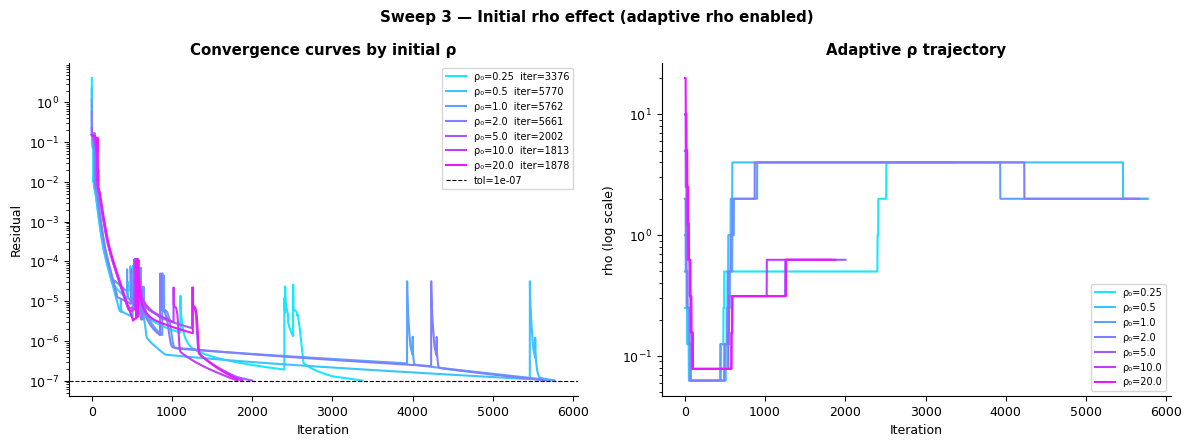

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
COLS3 = plt.cm.cool(np.linspace(0.1, 0.9, len(rhos)))

# Left: convergence curves
ax = axes[0]
for r, col in zip(sweep_rho, COLS3):
    if r['history']:
        iters = [h[0] for h in r['history']]
        resid = [h[1] for h in r['history']]
        ax.semilogy(iters, resid, color=col, lw=1.5,
                    label=f"ρ₀={r['rho']}  iter={r['iterations']}")
ax.axhline(BASE_TOL, color='k', lw=0.8, ls='--', label=f'tol={BASE_TOL:.0e}')
ax.set_xlabel('Iteration'); ax.set_ylabel('Residual')
ax.set_title('Convergence curves by initial ρ', fontweight='bold')
ax.legend(fontsize=7)

# Right: rho trajectory for each run
ax = axes[1]
for r, col in zip(sweep_rho, COLS3):
    if r['history']:
        iters = [h[0] for h in r['history']]
        rho_t = [h[2] for h in r['history']]
        ax.semilogy(iters, rho_t, color=col, lw=1.5,
                    label=f"ρ₀={r['rho']}")
ax.set_xlabel('Iteration'); ax.set_ylabel('rho (log scale)')
ax.set_title('Adaptive ρ trajectory', fontweight='bold')
ax.legend(fontsize=7)

plt.suptitle('Sweep 3 — Initial rho effect (adaptive rho enabled)',
             fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Sweep 4 — Temporal Resolution
Effect of Resolution on found cost.

In [25]:
resolutions = [0.25, 0.5, 1.0]   # hours: 15-min, 30-min, 1-hour
sweep_res   = []

# build once at smallest resolution (15 mins), then upsample
data_base = make_scenario(SEASON, seed=SEED, resolution_h=0.25)

def resample_data(data, target_res_h):
    """Resample an existing data dict to a coarser resolution."""
    if target_res_h == data['dt']:
        return data

    factor = int(round(target_res_h / data['dt']))
    T_old  = len(data['buy_price'])
    T_new  = T_old // factor
    N      = len(data['demand'])

    def _mean(arr):
        return np.array(arr).reshape(T_new, factor).mean(axis=1).tolist()

    def _sum(arr):
        return np.array(arr).reshape(T_new, factor).sum(axis=1).tolist()

    def _avail(arr):
        return (np.array(arr).reshape(T_new, factor).max(axis=1) > 0.001
                ).astype(int).tolist()

    # Prices: take one value per block (piecewise constant, not averaged)
    d = {**data,
         'dt':         target_res_h,
         'buy_price':  [data['buy_price'][t*factor]  for t in range(T_new)],
         'sell_price': [data['sell_price'][t*factor] for t in range(T_new)],
         'p2p_price':  [data['p2p_price'][t*factor]  for t in range(T_new)],
         'demand':          [_mean(data['demand'][i])           for i in range(N)],
         'generation':      [_mean(data['generation'][i])       for i in range(N)],
         'hp_base_power':   [_mean(data['hp_base_power'][i])    for i in range(N)],
         'hp_q_heat':       [_mean(data['hp_q_heat'][i])        for i in range(N)],
         'ev_availability': [_avail(data['ev_availability'][i]) for i in range(N)],
         'ev_driving_load': [_sum(data['ev_driving_load'][i])   for i in range(N)],
    }
    return d

for res in resolutions:
    print(f"  res={res}h ({int(res*60)}min) ...", flush=True)
    data_res = resample_data(data_base, res)   
    T_res    = len(data_res['buy_price'])

    t0  = time.time()
    r_c = centralized(data_res)
    t_c = time.time() - t0

    if T_res <= 48:
        t0  = time.time()
        r_d = distributed(data_res, rho=BASE_RHO, tolerance=BASE_TOL,
                          max_iterations=50000,
                          adaptive_rho=True, log_history=True)
        t_d       = time.time() - t0
        converged = r_d.get('converged', True)
        max_diff  = float(np.max(np.abs(r_d['costs'] - r_c['costs'])))
        dist_cost = r_d['costs'].sum()
        iter_count= r_d['iterations']
        status    = '✓' if converged else '⚠ cap'
    else:
        r_d, t_d, max_diff = None, float('nan'), float('nan')
        dist_cost, iter_count, status = float('nan'), -1, '— skipped'

    print(f"  T={T_res:<4}  cent={r_c['costs'].sum():.4f}  "
          f"dist={dist_cost:.4f}  iter={iter_count:>6}  "
          f"cent={t_c:.1f}s  dist={t_d:.1f}s  {status}", flush=True)

    sweep_res.append({
        'resolution_h': res, 'T': T_res,
        'total_cent':   float(r_c['costs'].sum()),
        'total_dist':   dist_cost,
        'max_ind_diff': max_diff,
        'iterations':   iter_count,
        'converged':    status,
        't_cent':       t_c,
        't_dist':       t_d,
        'history':      r_d['history'] if r_d else [],
    })
    print('─' * 80, flush=True)

Building winter scenario (T=96, dt=0.25h, resolution=15min)...
  P1: Residential ++ (bus 5)
    HP: Air_Alternative_1 (Air alternative, Hanover)
  P2: Office building (bus 11)
    ⚠ No EV activity detected — using fallback schedule
  P3: Residential HP only (bus 17)
    HP: Air_Semi-Parallel_1 (Air semi-parallel, Hanover)
  P4: Residential PV only (bus 32)
  Done. N=4, T=96, dt=0.25h, max_demand=6.6 kW
  res=0.25h (15min) ...
  T=96    cent=58.6035  dist=nan  iter=    -1  cent=0.7s  dist=nans  — skipped
────────────────────────────────────────────────────────────────────────────────
  res=0.5h (30min) ...
  T=48    cent=58.6009  dist=58.6009  iter=  4819  cent=0.1s  dist=159.7s  ✓
────────────────────────────────────────────────────────────────────────────────
  res=1.0h (60min) ...
  T=24    cent=58.5969  dist=58.5969  iter=  3883  cent=0.1s  dist=78.6s  ✓
────────────────────────────────────────────────────────────────────────────────


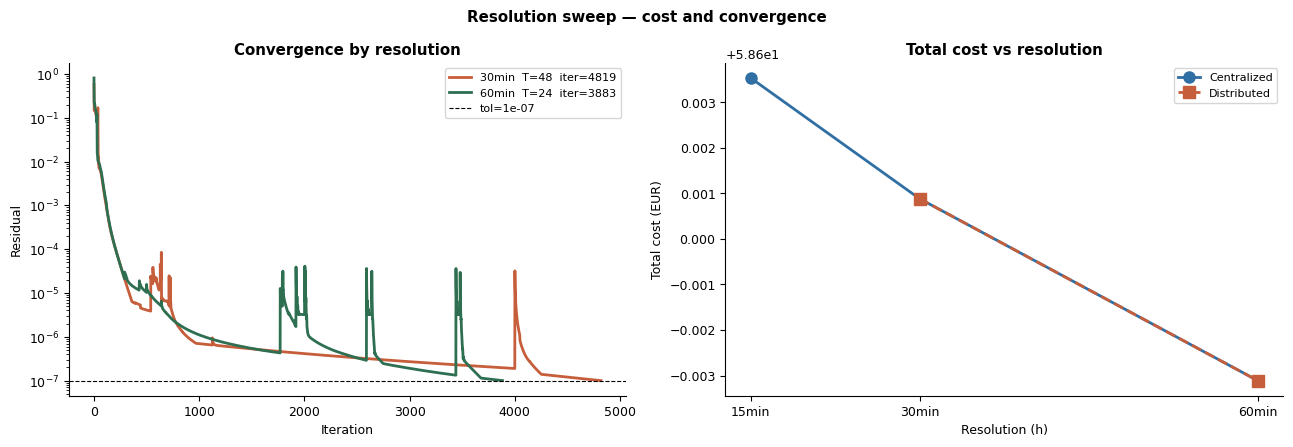

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: convergence curves (only runs that have history)
ax = axes[0]
COLS_R = ['#2F6FA3', '#C65D3B', '#2E6F52']
for r, col in zip(sweep_res, COLS_R):
    if r['history']:
        iters = [h[0] for h in r['history']]
        resid = [h[1] for h in r['history']]
        ax.semilogy(iters, resid, color=col, lw=2,
                    label=f"{int(r['resolution_h']*60)}min  "
                          f"T={r['T']}  iter={r['iterations']}")
ax.axhline(BASE_TOL, color='k', lw=0.8, ls='--',
           label=f'tol={BASE_TOL:.0e}')
ax.set_xlabel('Iteration'); ax.set_ylabel('Residual')
ax.set_title('Convergence by resolution', fontweight='bold')
ax.legend(fontsize=8)

# Right: total cost vs resolution
ax = axes[1]
res_h   = [r['resolution_h'] for r in sweep_res]
costs_c = [r['total_cent']   for r in sweep_res]
costs_d = [r['total_dist']   for r in sweep_res
           if not np.isnan(r['total_dist'])]
res_d   = [r['resolution_h'] for r in sweep_res
           if not np.isnan(r['total_dist'])]

ax.plot(res_h, costs_c, 'o-', color='#2F6FA3', lw=2, ms=8,
        label='Centralized')
if costs_d:
    ax.plot(res_d, costs_d, 's--', color='#C65D3B', lw=2, ms=8,
            label='Distributed')
ax.set_xlabel('Resolution (h)')
ax.set_ylabel('Total cost (EUR)')
ax.set_title('Total cost vs resolution', fontweight='bold')
ax.set_xticks(res_h)
ax.set_xticklabels([f'{int(r*60)}min' for r in res_h])
ax.legend(fontsize=8)

plt.suptitle('Resolution sweep — cost and convergence', fontweight='bold')
plt.tight_layout()
plt.show()